In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Keerthana_Retail_Sales_Dataset (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (100, 9)


,Transaction ID,Date,Customer ID,Gender,Product Category,Quantity,Price per Unit,Total Amount,Payment Method
0,TXN0001,2025-03-04,C015,Female,Electronics,3,120,360,Cash
1,TXN0002,2025-04-19,C003,Female,Home & Kitchen,5,30,150,Cash
2,TXN0003,2025-06-04,C002,Female,Clothing,5,35,175,UPI
3,TXN0004,2025-03-13,C001,Female,Clothing,5,75,375,UPI
4,TXN0005,2025-02-25,C022,Female,Beauty,2,25,50,Cash


In [6]:
# Explore dataset information
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    100 non-null    str  
 1   Date              100 non-null    str  
 2   Customer ID       100 non-null    str  
 3   Gender            100 non-null    str  
 4   Product Category  100 non-null    str  
 5   Quantity          100 non-null    int64
 6   Price per Unit    100 non-null    int64
 7   Total Amount      100 non-null    int64
 8   Payment Method    100 non-null    str  
dtypes: int64(3), str(6)
memory usage: 7.2 KB

Dataset Shape:
(100, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Payment Method']

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Product Category    0
Quantity            0
Price per Unit      0

In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (100, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount', 'Payment Method']

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Payment Method      0
dtype: int64

Duplicate Rows:
0


In [8]:
# Basic Retail Sales Analysis

print("Total Sales Amount:", df["Total Amount"].sum())

print("\nTotal Quantity Sold:", df["Quantity"].sum())

print("\nNumber of Transactions:", df["Transaction ID"].nunique())

print("\nSales by Product Category:")
print(
    df.groupby("Product Category")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("\nSales by Payment Method:")
print(
    df.groupby("Payment Method")["Total Amount"]
    .sum()
    .sort_values(ascending=False)
)

Total Sales Amount: 22269

Total Quantity Sold: 310

Number of Transactions: 100

Sales by Product Category:
Product Category
Electronics       11400
Home & Kitchen     4305
Clothing           3450
Beauty             2090
Food               1024
Name: Total Amount, dtype: int64

Sales by Payment Method:
Payment Method
Credit Card    6402
UPI            6258
Debit Card     4989
Cash           4620
Name: Total Amount, dtype: int64


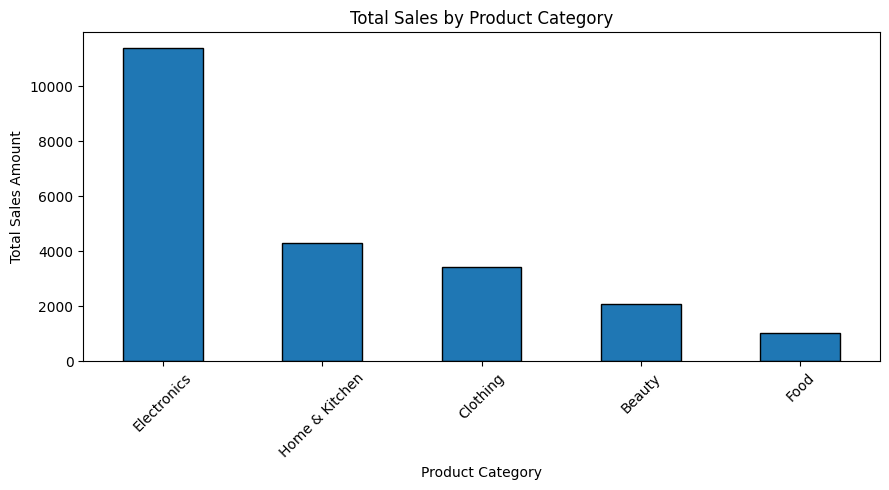

In [9]:
# Sales by Product Category

category_sales = df.groupby("Product Category")["Total Amount"].sum()

plt.figure(figsize=(9, 5))
category_sales.sort_values(ascending=False).plot(
    kind="bar", edgecolor="black"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

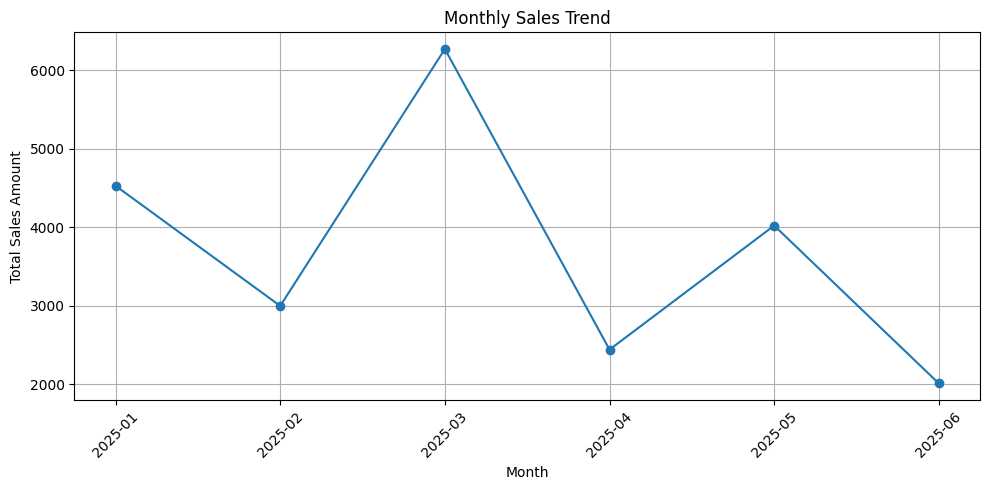

In [10]:
# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Extract month
df["Month"] = df["Date"].dt.to_period("M")

# Calculate monthly sales
monthly_sales = df.groupby("Month")["Total Amount"].sum()

# Create line chart
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Sales by Gender:
Gender
Female    12463
Male       9806
Name: Total Amount, dtype: int64


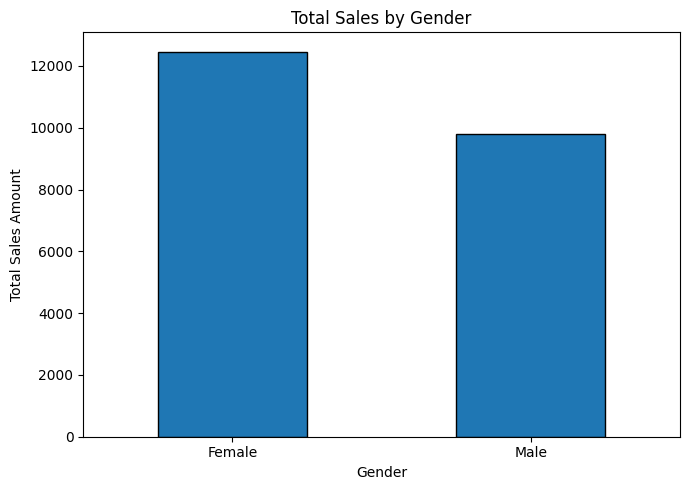

In [11]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

print("Sales by Gender:")
print(gender_sales)

plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar", edgecolor="black")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Sales by Payment Method:
Payment Method
Cash           4620
Credit Card    6402
Debit Card     4989
UPI            6258
Name: Total Amount, dtype: int64


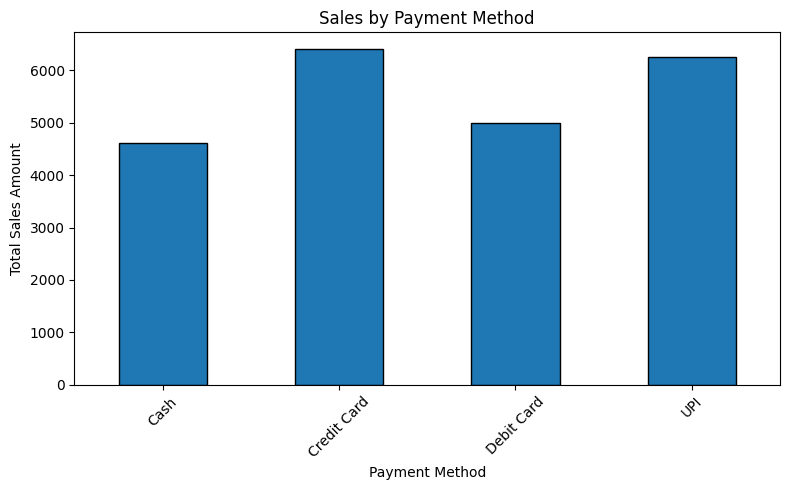

In [12]:
payment_sales = df.groupby("Payment Method")["Total Amount"].sum()

print("Sales by Payment Method:")
print(payment_sales)

plt.figure(figsize=(8, 5))
payment_sales.plot(kind="bar", edgecolor="black")

plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 5 Customers:
Customer ID
C043    4013
C005    1920
C024    1610
C017    1505
C036    1040
Name: Total Amount, dtype: int64


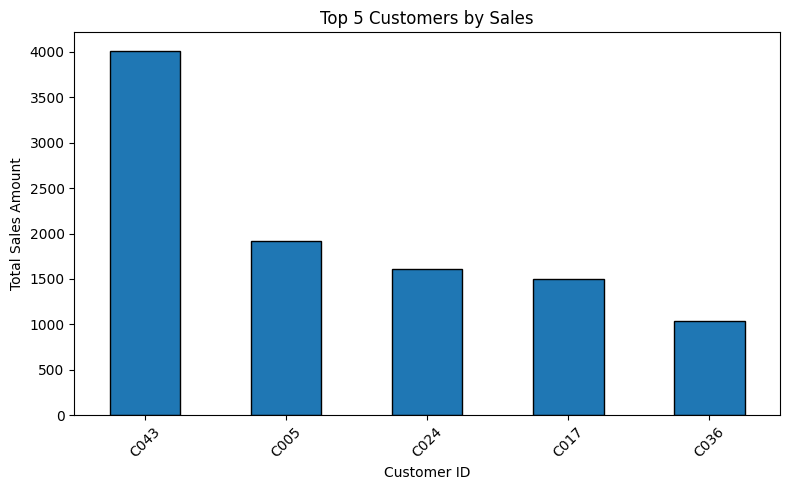

In [13]:
customer_sales = df.groupby("Customer ID")["Total Amount"].sum()

top_customers = customer_sales.sort_values(ascending=False).head(5)

print("Top 5 Customers:")
print(top_customers)

plt.figure(figsize=(8, 5))
top_customers.plot(kind="bar", edgecolor="black")

plt.title("Top 5 Customers by Sales")
plt.xlabel("Customer ID")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Quantity Sold by Product Category:
Product Category
Beauty            63
Clothing          79
Electronics       33
Food              75
Home & Kitchen    60
Name: Quantity, dtype: int64


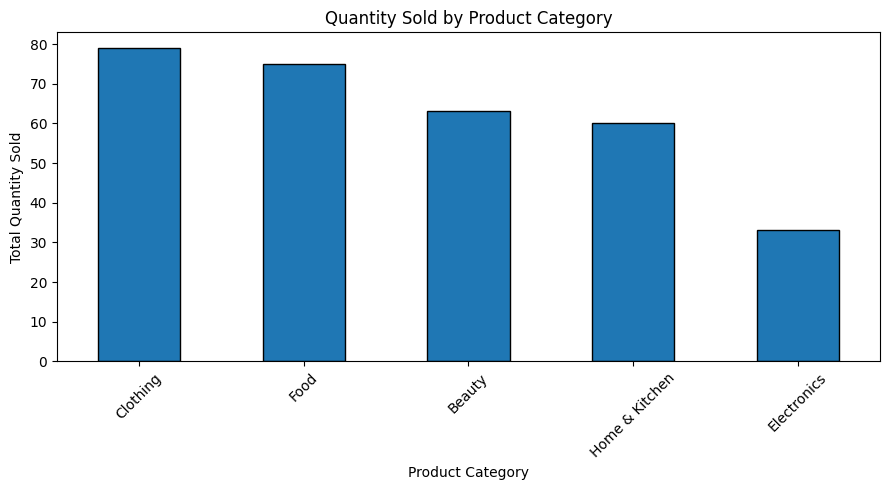

In [14]:
category_quantity = df.groupby("Product Category")["Quantity"].sum()

print("Quantity Sold by Product Category:")
print(category_quantity)

plt.figure(figsize=(9, 5))
category_quantity.sort_values(ascending=False).plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
average_sales = df["Total Amount"].mean()
highest_sales = df["Total Amount"].max()
lowest_sales = df["Total Amount"].min()

print("Average Sales Amount:", average_sales)
print("Highest Sales Amount:", highest_sales)
print("Lowest Sales Amount:", lowest_sales)


Average Sales Amount: 222.69
Highest Sales Amount: 1900
Lowest Sales Amount: 8


Correlation Matrix:
                Quantity  Price per Unit  Total Amount
Quantity        1.000000       -0.172244      0.094754
Price per Unit -0.172244        1.000000      0.887697
Total Amount    0.094754        0.887697      1.000000


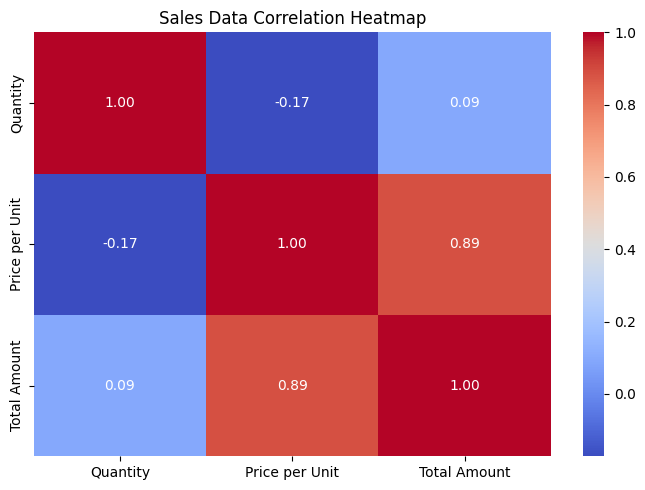

In [16]:
correlation = df[["Quantity", "Price per Unit", "Total Amount"]].corr()

print("Correlation Matrix:")
print(correlation)

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Sales Data Correlation Heatmap")
plt.tight_layout()
plt.show()

In [17]:
print("========== RETAIL SALES ANALYSIS SUMMARY ==========")

print("Total Revenue:", df["Total Amount"].sum())

print("Total Products Sold:", df["Quantity"].sum())

print("Total Transactions:", df["Transaction ID"].nunique())

print("Average Transaction Amount:", df["Total Amount"].mean())

print("\nBest Selling Product Category:")
print(df.groupby("Product Category")["Quantity"].sum().idxmax())

print("\nHighest Revenue Product Category:")
print(df.groupby("Product Category")["Total Amount"].sum().idxmax())

print("\nMost Used Payment Method:")
print(df["Payment Method"].value_counts().idxmax())

print("\n========== ANALYSIS COMPLETED ==========")

========== RETAIL SALES ANALYSIS SUMMARY ==========
Total Revenue: 22269
Total Products Sold: 310
Total Transactions: 100
Average Transaction Amount: 222.69

Best Selling Product Category:
Clothing

Highest Revenue Product Category:
Electronics

Most Used Payment Method:
Cash

========== ANALYSIS COMPLETED ==========


# Conclusion

The Retail Sales Exploratory Data Analysis project was successfully completed using Python.

In this project, the retail sales dataset was analyzed to understand sales performance, customer purchasing behaviour, product categories, and payment methods.

The analysis was performed using Pandas, NumPy, Matplotlib, and Seaborn.

The visualizations helped identify sales trends, top-selling product categories, customer contributions, and payment preferences.

This project provided useful insights into retail sales data and improved understanding of Exploratory Data Analysis (EDA).